# TASK 06 — Time-Based Late Delivery Analysis and Confidence Interval Estimation

**Project:** Early Prediction of Late Delivery Risk in Brazilian E-Commerce

**Dataset:** Brazilian E-Commerce Public Dataset by Olist

## Research Objectives

This notebook aims to:

1. Validate the official order-level research dataset.
2. Analyze monthly order volume and late-delivery rates.
3. Assess missing labels and monthly observation coverage.
4. Estimate 95% Wilson confidence intervals.
5. Visualize monthly patterns with appropriate warnings.
6. Compare findings with the existing EDA results.

All monthly rates are calculated using orders with valid
late-delivery labels only.

This task focuses on descriptive analysis and confidence
interval estimation. It does not perform hypothesis testing,
causal inference, forecasting, or machine learning.

## 1. Data Loading and Initial Validation

### Objective

Load the official research dataset and validate its
structure, delivery labels, and purchase-month consistency.

### Validation Rules

- One row represents one unique order.
- `is_late` must contain only 0, 1, or missing values.
- `purchase_month` must match the year and month of
  `order_purchase_timestamp`.
- Missing values must not be automatically replaced with zero.
- The original research dataset must remain unchanged.

In [1]:
# =========================================================
# SECTION 1: DATA LOADING AND INITIAL VALIDATION
# =========================================================

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ---------------------------------------------------------
# 1.1. Locate project root
# ---------------------------------------------------------

PROJECT_ROOT = Path.cwd()

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "research_data.csv"
)

if not DATA_PATH.exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

    DATA_PATH = (
        PROJECT_ROOT
        / "data"
        / "processed"
        / "research_data.csv"
    )

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Cannot locate data/processed/research_data.csv"
    )


# ---------------------------------------------------------
# 1.2. Load official research dataset
# ---------------------------------------------------------

df = pd.read_csv(
    DATA_PATH,
    dtype={
        "order_id": "string",
        "purchase_month": "string"
    }
)

df["order_purchase_timestamp"] = pd.to_datetime(
    df["order_purchase_timestamp"],
    errors="coerce"
)


# ---------------------------------------------------------
# 1.3. Basic dataset statistics
# ---------------------------------------------------------

print("DATASET OVERVIEW")
print("-" * 45)

print("Total rows:", len(df))
print("Total columns:", len(df.columns))
print("Unique orders:", df["order_id"].nunique())

print("\nTARGET DISTRIBUTION")

print(
    df["is_late"].value_counts(dropna=False)
)


# ---------------------------------------------------------
# 1.4. Validate order uniqueness
# ---------------------------------------------------------

duplicate_orders = df["order_id"].duplicated().sum()

missing_order_ids = df["order_id"].isna().sum()

print("\nORDER ID VALIDATION")
print("Duplicate orders:", duplicate_orders)
print("Missing order IDs:", missing_order_ids)

assert duplicate_orders == 0
assert missing_order_ids == 0


# ---------------------------------------------------------
# 1.5. Validate target values
# ---------------------------------------------------------

valid_target_values = (
    df["is_late"].isin([0, 1])
    | df["is_late"].isna()
)

invalid_target_count = (~valid_target_values).sum()

print("\nTARGET VALIDATION")
print("Invalid target values:", invalid_target_count)

assert invalid_target_count == 0


# ---------------------------------------------------------
# 1.6. Validate purchase month consistency
# ---------------------------------------------------------

calculated_month = (
    df["order_purchase_timestamp"]
    .dt.strftime("%Y-%m")
    .astype("string")
)

recorded_month = df["purchase_month"].astype("string")

month_matches = recorded_month.eq(calculated_month)

month_mismatch = ~month_matches.fillna(False)

mismatch_count = month_mismatch.sum()

print("\nPURCHASE MONTH VALIDATION")

print("Month mismatches:", mismatch_count)

if mismatch_count > 0:
    print("\nExample mismatched records:")

    print(
        df.loc[
            month_mismatch,
            [
                "order_id",
                "order_purchase_timestamp",
                "purchase_month"
            ]
        ].head(10).to_string(index=False)
    )

assert mismatch_count == 0


# ---------------------------------------------------------
# 1.7. Final checks
# ---------------------------------------------------------

print("\nFINAL DATASET CHECKS")

assert len(df) == 99441
assert df["order_id"].nunique() == len(df)
assert len(df.columns) == 34

print("Dataset structure: PASSED")
print("Order uniqueness: PASSED")
print("Target validation: PASSED")
print("Purchase month consistency: PASSED")

print("\nSection 1 completed successfully.")

DATASET OVERVIEW
---------------------------------------------
Total rows: 99441
Total columns: 34
Unique orders: 99441

TARGET DISTRIBUTION
is_late
0.0    89936
1.0     6534
NaN     2971
Name: count, dtype: int64

ORDER ID VALIDATION
Duplicate orders: 0
Missing order IDs: 0

TARGET VALIDATION
Invalid target values: 0

PURCHASE MONTH VALIDATION
Month mismatches: 0

FINAL DATASET CHECKS
Dataset structure: PASSED
Order uniqueness: PASSED
Target validation: PASSED
Purchase month consistency: PASSED

Section 1 completed successfully.


## 2. Complete Monthly Data Aggregation

### Objective

Construct a complete monthly summary from September 2016
to October 2018, including months with no recorded orders.

### Methodology

- Include all orders when calculating monthly order volume.
- Count valid, late, and missing delivery labels separately.
- Calculate late-delivery rates using valid orders only.
- Preserve months with zero orders or zero valid labels.
- Calculate 95% Wilson confidence intervals when valid orders exist.
- Record warnings for sparse observations and uncertain coverage.

### Important Rules

- Late delivery rates and confidence intervals are stored
  as proportions between 0 and 1.
- Months without valid labels have undefined late-delivery
  rates and confidence intervals.
- A zero observed late-delivery rate is different from
  an undefined rate.
- Missing values are not replaced with zero.

In [2]:

# =========================================================
# SECTION 2: COMPLETE MONTHLY DATA AGGREGATION
# =========================================================

# ---------------------------------------------------------
# 2.1. Generate a complete sequence of purchase months
# ---------------------------------------------------------

first_month = df["order_purchase_timestamp"].min().to_period("M")
last_month = df["order_purchase_timestamp"].max().to_period("M")

all_months = pd.period_range(
    start=first_month,
    end=last_month,
    freq="M"
).strftime("%Y-%m")

print("First month:", first_month)
print("Last month:", last_month)
print("Total calendar months:", len(all_months))


# ---------------------------------------------------------
# 2.2. Aggregate order and target counts
# ---------------------------------------------------------

monthly_summary = (
    df.groupby("purchase_month")
    .agg(
        total_orders=("order_id", "size"),
        valid_orders=(
            "is_late",
            lambda x: x.isin([0, 1]).sum()
        ),
        late_orders=(
            "is_late",
            lambda x: x.eq(1).sum()
        ),
        missing_target_orders=(
            "is_late",
            lambda x: x.isna().sum()
        )
    )
    .reindex(all_months, fill_value=0)
    .rename_axis("purchase_month")
    .reset_index()
)

# Ensure integer count columns
count_columns = [
    "total_orders",
    "valid_orders",
    "late_orders",
    "missing_target_orders"
]

monthly_summary[count_columns] = (
    monthly_summary[count_columns].astype(int)
)


# ---------------------------------------------------------
# 2.3. Calculate missing-target percentage
# ---------------------------------------------------------

monthly_summary["missing_target_percent"] = (
    monthly_summary["missing_target_orders"]
    / monthly_summary["total_orders"].replace(0, np.nan)
    * 100
)


# ---------------------------------------------------------
# 2.4. Calculate monthly late-delivery rate
# ---------------------------------------------------------

monthly_summary["late_rate"] = (
    monthly_summary["late_orders"]
    / monthly_summary["valid_orders"].replace(0, np.nan)
)


# ---------------------------------------------------------
# 2.5. Calculate 95% Wilson confidence intervals
# ---------------------------------------------------------

z = 1.96

n = monthly_summary["valid_orders"].to_numpy(dtype=float)
x = monthly_summary["late_orders"].to_numpy(dtype=float)

# Prevent division by zero
safe_n = np.where(n > 0, n, np.nan)

p = x / safe_n

denominator = 1 + z**2 / safe_n

center = (
    p + z**2 / (2 * safe_n)
) / denominator

margin = (
    z / denominator
    * np.sqrt(
        p * (1 - p) / safe_n
        + z**2 / (4 * safe_n**2)
    )
)

monthly_summary["ci_lower"] = center - margin
monthly_summary["ci_upper"] = center + margin

# Protect against numerical rounding at boundaries
monthly_summary["ci_lower"] = (
    monthly_summary["ci_lower"].clip(lower=0, upper=1)
)

monthly_summary["ci_upper"] = (
    monthly_summary["ci_upper"].clip(lower=0, upper=1)
)


# ---------------------------------------------------------
# 2.6. Add preliminary coverage warnings
# ---------------------------------------------------------

def create_coverage_note(row):
    notes = []

    if row["total_orders"] == 0:
        return "No recorded orders"

    if row["valid_orders"] == 0:
        notes.append("No valid delivery labels")

    if row["valid_orders"] < 100:
        notes.append("Sparse valid labels (<100)")

    if row["purchase_month"] in [
        str(first_month),
        str(last_month)
    ]:
        notes.append("Boundary month; coverage uncertain")

    if (
        pd.notna(row["missing_target_percent"])
        and row["missing_target_percent"] > 10
    ):
        notes.append("High missing-label share (>10%)")

    if not notes:
        return "No specific flag"

    return "; ".join(notes)


monthly_summary["coverage_note"] = (
    monthly_summary.apply(create_coverage_note, axis=1)
)


# ---------------------------------------------------------
# 2.7. Arrange columns according to TASK 06
# ---------------------------------------------------------

required_columns = [
    "purchase_month",
    "total_orders",
    "valid_orders",
    "late_orders",
    "missing_target_orders",
    "missing_target_percent",
    "late_rate",
    "ci_lower",
    "ci_upper",
    "coverage_note"
]

monthly_summary = monthly_summary[required_columns]


# ---------------------------------------------------------
# 2.8. Validate monthly aggregation
# ---------------------------------------------------------

assert len(monthly_summary) == len(all_months)

assert monthly_summary["total_orders"].sum() == len(df)

assert (
    monthly_summary["valid_orders"].sum()
    == df["is_late"].isin([0, 1]).sum()
)

assert (
    monthly_summary["late_orders"].sum()
    == df["is_late"].eq(1).sum()
)

assert (
    monthly_summary["missing_target_orders"].sum()
    == df["is_late"].isna().sum()
)

assert (
    monthly_summary["valid_orders"]
    + monthly_summary["missing_target_orders"]
    == monthly_summary["total_orders"]
).all()

assert (
    monthly_summary["late_orders"]
    <= monthly_summary["valid_orders"]
).all()

assert (
    monthly_summary["valid_orders"]
    <= monthly_summary["total_orders"]
).all()

valid_months = monthly_summary["valid_orders"] > 0

assert (
    monthly_summary.loc[valid_months, "ci_lower"]
    <= monthly_summary.loc[valid_months, "late_rate"]
).all()

assert (
    monthly_summary.loc[valid_months, "late_rate"]
    <= monthly_summary.loc[valid_months, "ci_upper"]
).all()

assert (
    monthly_summary.loc[
        valid_months, ["late_rate", "ci_lower", "ci_upper"]
    ].ge(0).all().all()
)

assert (
    monthly_summary.loc[
        valid_months, ["late_rate", "ci_lower", "ci_upper"]
    ].le(1).all().all()
)

assert (
    monthly_summary.loc[
        ~valid_months, ["late_rate", "ci_lower", "ci_upper"]
    ].isna().all().all()
)


# ---------------------------------------------------------
# 2.9. Display summary
# ---------------------------------------------------------

print("\nCOMPLETE MONTHLY SUMMARY")
print("-" * 70)

print(
    monthly_summary.to_string(
        index=False,
        na_rep="NaN",
        float_format=lambda value: f"{value:.4f}"
    )
)

print("\nAGGREGATION TOTALS")
print("Total orders:", monthly_summary["total_orders"].sum())
print("Valid orders:", monthly_summary["valid_orders"].sum())
print("Late orders:", monthly_summary["late_orders"].sum())
print(
    "Missing labels:",
    monthly_summary["missing_target_orders"].sum()
)

print("\nMonthly aggregation validation passed.")


First month: 2016-09
Last month: 2018-10
Total calendar months: 26

COMPLETE MONTHLY SUMMARY
----------------------------------------------------------------------
purchase_month  total_orders  valid_orders  late_orders  missing_target_orders  missing_target_percent  late_rate  ci_lower  ci_upper                                                                                                             coverage_note
       2016-09             4             1            1                      3                 75.0000     1.0000    0.2065    1.0000                           Sparse valid labels (<100); Boundary month; coverage uncertain; High missing-label share (>10%)
       2016-10           324           265            2                     59                 18.2099     0.0075    0.0021    0.0271                                                                                           High missing-label share (>10%)
       2016-11             0             0            0             

## 3. Data Completeness and Observation Coverage

### Objective

Assess the completeness of monthly delivery labels and
the temporal coverage of the research dataset.

### Analysis

This section examines:

1. The first and last recorded purchase dates in each month.
2. The number of distinct days with recorded purchases.
3. Months with no recorded orders.
4. Months with fewer than 100 valid delivery labels.
5. Months with missing delivery labels.

### Interpretation Rules

- Sparse observations do not automatically indicate
  incomplete data collection.
- Missing delivery labels may affect the interpretation
  of late-delivery rates.
- Observed purchase dates do not prove that all transactions
  were captured.
- Boundary months and sparse months require caution.
- Coverage uncertainty must be reported when completeness
  cannot be established.

In [3]:

# =========================================================
# SECTION 3: DATA COMPLETENESS AND OBSERVATION COVERAGE
# =========================================================

# ---------------------------------------------------------
# 3.1. Extract purchase dates
# ---------------------------------------------------------

df_coverage = df.copy()

df_coverage["purchase_date"] = (
    df_coverage["order_purchase_timestamp"].dt.date
)


# ---------------------------------------------------------
# 3.2. Calculate observed purchase-date coverage
# ---------------------------------------------------------

date_coverage = (
    df_coverage
    .groupby("purchase_month")
    .agg(
        first_purchase=(
            "order_purchase_timestamp", "min"
        ),
        last_purchase=(
            "order_purchase_timestamp", "max"
        ),
        observed_purchase_days=(
            "purchase_date", "nunique"
        )
    )
    .reset_index()
)


# ---------------------------------------------------------
# 3.3. Combine with the monthly summary
# ---------------------------------------------------------

monthly_coverage = monthly_summary[
    [
        "purchase_month",
        "total_orders",
        "valid_orders",
        "missing_target_orders",
        "missing_target_percent",
        "coverage_note"
    ]
].merge(
    date_coverage,
    on="purchase_month",
    how="left",
    validate="one_to_one"
)

# Months without recorded orders have zero observed days.
monthly_coverage["observed_purchase_days"] = (
    monthly_coverage["observed_purchase_days"]
    .fillna(0)
    .astype(int)
)

# Number of calendar days in each month
monthly_coverage["calendar_days"] = (
    pd.PeriodIndex(
        monthly_coverage["purchase_month"],
        freq="M"
    ).days_in_month
)


# ---------------------------------------------------------
# 3.4. Identify months requiring additional attention
# ---------------------------------------------------------

no_order_months = monthly_coverage[
    monthly_coverage["total_orders"] == 0
]

no_label_months = monthly_coverage[
    (monthly_coverage["total_orders"] > 0)
    & (monthly_coverage["valid_orders"] == 0)
]

sparse_months = monthly_coverage[
    monthly_coverage["valid_orders"] < 100
]

high_missing_months = monthly_coverage[
    monthly_coverage["missing_target_percent"] > 10
]

boundary_months = monthly_coverage[
    monthly_coverage["purchase_month"].isin(
        [str(first_month), str(last_month)]
    )
]


# ---------------------------------------------------------
# 3.5. Validate coverage information
# ---------------------------------------------------------

assert len(monthly_coverage) == len(monthly_summary)

assert monthly_coverage["purchase_month"].is_unique

assert (
    monthly_coverage["observed_purchase_days"]
    <= monthly_coverage["calendar_days"]
).all()

assert (
    monthly_coverage["observed_purchase_days"]
    <= monthly_coverage["total_orders"]
).all()

assert (
    monthly_coverage["first_purchase"].notna()
    == (monthly_coverage["total_orders"] > 0)
).all()

assert (
    monthly_coverage["last_purchase"].notna()
    == (monthly_coverage["total_orders"] > 0)
).all()


# ---------------------------------------------------------
# 3.6. Display completeness statistics
# ---------------------------------------------------------

print("MONTHLY COVERAGE OVERVIEW")
print("-" * 60)

print("Total calendar months:", len(monthly_coverage))
print("Months without orders:", len(no_order_months))
print("Months without valid labels:", len(no_label_months))
print("Months with <100 valid labels:", len(sparse_months))
print("Months with >10% missing labels:", len(high_missing_months))


# ---------------------------------------------------------
# 3.7. Inspect sparse and missing-label months
# ---------------------------------------------------------

print("\nMONTHS WITH FEWER THAN 100 VALID LABELS")
print("-" * 60)

print(
    sparse_months[
        [
            "purchase_month",
            "total_orders",
            "valid_orders",
            "missing_target_percent",
            "coverage_note"
        ]
    ].to_string(index=False)
)


# ---------------------------------------------------------
# 3.8. Inspect boundary-month coverage
# ---------------------------------------------------------

print("\nBOUNDARY MONTH COVERAGE")
print("-" * 60)

print(
    boundary_months[
        [
            "purchase_month",
            "first_purchase",
            "last_purchase",
            "observed_purchase_days",
            "calendar_days",
            "missing_target_percent",
            "coverage_note"
        ]
    ].to_string(index=False)
)


# ---------------------------------------------------------
# 3.9. Inspect high missing-label percentages
# ---------------------------------------------------------

print("\nMONTHS WITH MORE THAN 10% MISSING LABELS")
print("-" * 60)

print(
    high_missing_months[
        [
            "purchase_month",
            "total_orders",
            "valid_orders",
            "missing_target_percent"
        ]
    ].to_string(index=False)
)

print("\nCoverage validation passed.")
print("Section 3 completed successfully.")


MONTHLY COVERAGE OVERVIEW
------------------------------------------------------------
Total calendar months: 26
Months without orders: 1
Months without valid labels: 2
Months with <100 valid labels: 5
Months with >10% missing labels: 4

MONTHS WITH FEWER THAN 100 VALID LABELS
------------------------------------------------------------
purchase_month  total_orders  valid_orders  missing_target_percent                                                                                                             coverage_note
       2016-09             4             1                    75.0                           Sparse valid labels (<100); Boundary month; coverage uncertain; High missing-label share (>10%)
       2016-11             0             0                     NaN                                                                                                        No recorded orders
       2016-12             1             1                     0.0                            

## 4. Monthly Data Visualization

### Objective

Visualize monthly late-delivery patterns and data
completeness across the full observation period.

### Visualizations

1. Total order volume and orders with valid delivery labels.
2. Number of late deliveries per month.
3. Percentage of orders with missing delivery labels.
4. Monthly late-delivery rates with 95% Wilson confidence intervals.

### Visualization Rules

- Use a continuous calendar-based time axis.
- Include all 26 months from September 2016 to October 2018.
- Preserve missing rates rather than replacing them with zero.
- Highlight months with fewer than 100 valid delivery labels.
- Display uncertainty using Wilson confidence intervals.
- Do not interpret observed differences as causal effects
  or established seasonality.

Sparse months (<100 valid labels):
purchase_month  valid_orders
       2016-09             1
       2016-11             0
       2016-12             1
       2018-09             0
       2018-10             0


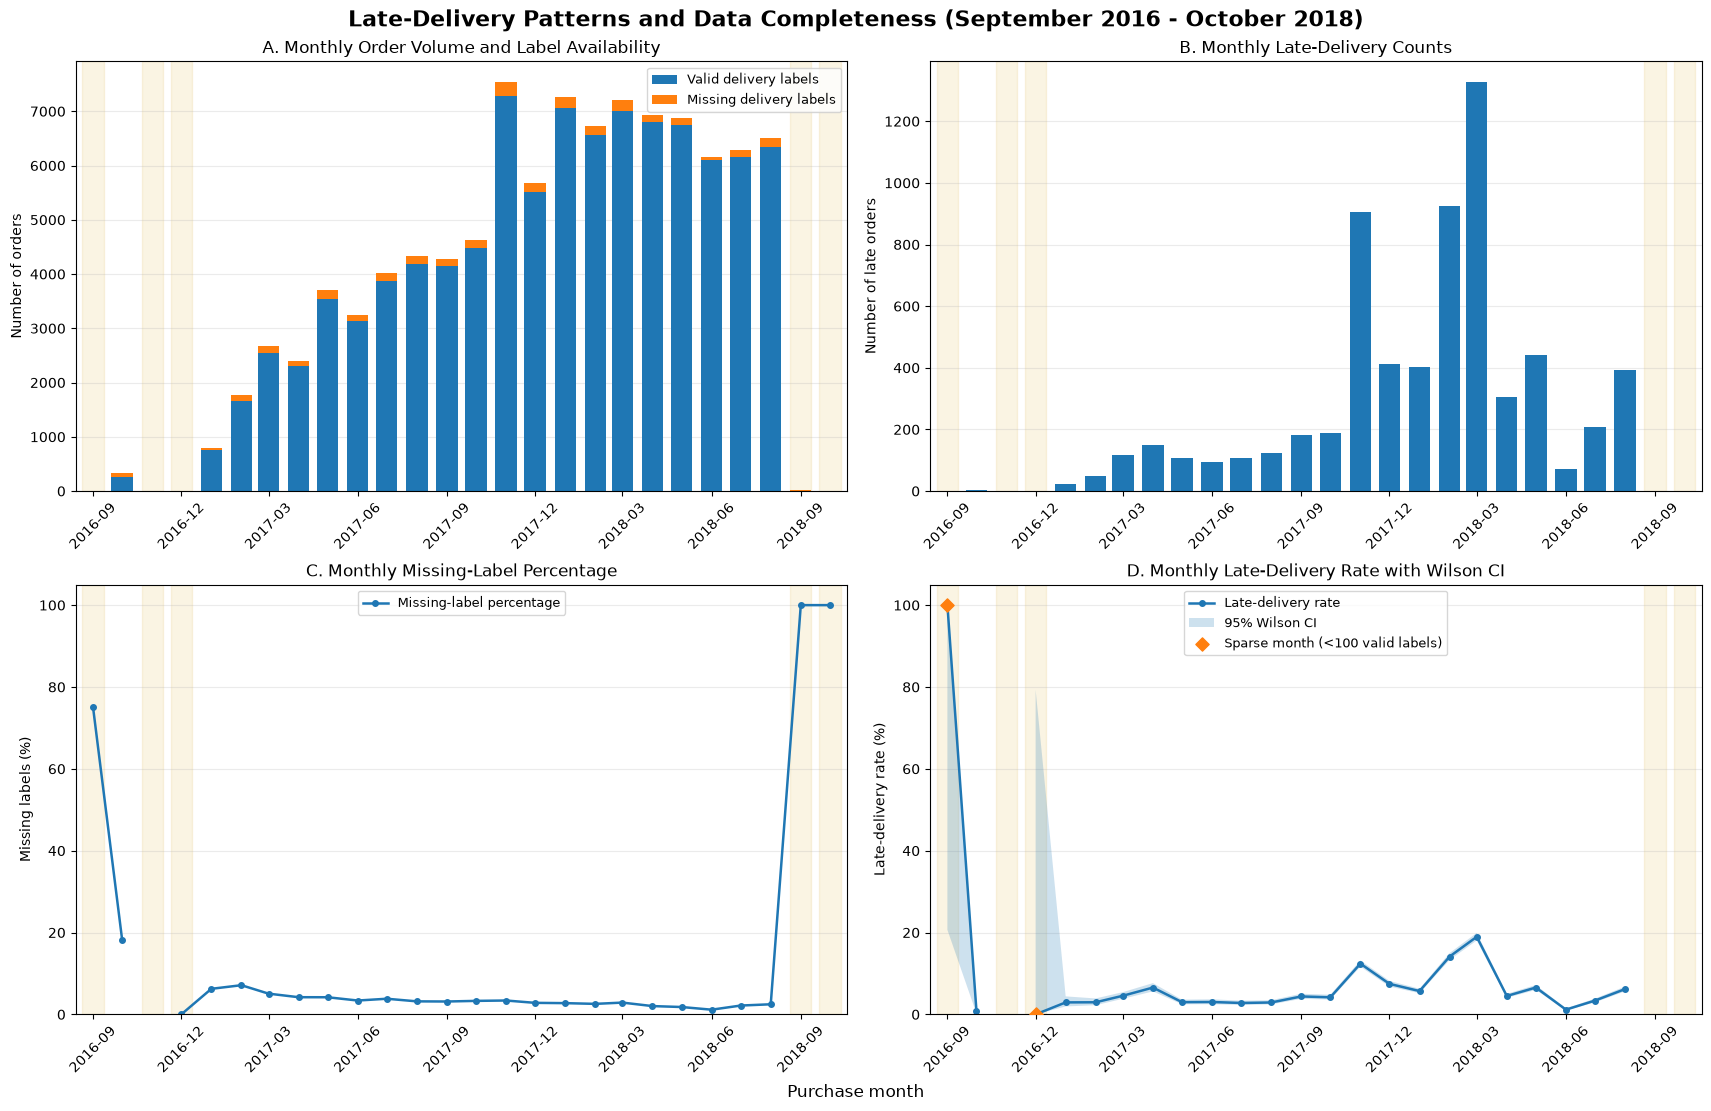


Figure saved successfully:
d:\Group5_STAT3013_EDA\outputs\figures\monthly_late_delivery_overview.png

Section 4 completed successfully.


In [4]:

# =========================================================
# SECTION 4: MONTHLY DATA VISUALIZATION
# =========================================================

import matplotlib.dates as mdates


# ---------------------------------------------------------
# 4.1. Prepare calendar-based x-axis
# ---------------------------------------------------------

month_dates = pd.to_datetime(
    monthly_summary["purchase_month"] + "-01",
    format="%Y-%m-%d"
)

# Convert dates into Matplotlib date coordinates.
x = mdates.date2num(month_dates.to_numpy())

total_counts = monthly_summary[
    "total_orders"
].to_numpy()

valid_counts = monthly_summary[
    "valid_orders"
].to_numpy()

missing_counts = monthly_summary[
    "missing_target_orders"
].to_numpy()

late_counts = monthly_summary[
    "late_orders"
].to_numpy()

missing_pct = monthly_summary[
    "missing_target_percent"
].to_numpy(dtype=float)

late_pct = (
    monthly_summary["late_rate"].to_numpy(dtype=float)
    * 100
)

ci_lower_pct = (
    monthly_summary["ci_lower"].to_numpy(dtype=float)
    * 100
)

ci_upper_pct = (
    monthly_summary["ci_upper"].to_numpy(dtype=float)
    * 100
)


# ---------------------------------------------------------
# 4.2. Identify sparse months
# ---------------------------------------------------------

sparse_mask = valid_counts < 100

sparse_valid_mask = (
    sparse_mask & (valid_counts > 0)
)

print("Sparse months (<100 valid labels):")

print(
    monthly_summary.loc[
        sparse_mask,
        ["purchase_month", "valid_orders"]
    ].to_string(index=False)
)


# ---------------------------------------------------------
# 4.3. Create four subplots
# ---------------------------------------------------------

fig_monthly, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(17, 11),
    sharex=True,
    constrained_layout=True
)

ax1, ax2, ax3, ax4 = axes.flat


# ---------------------------------------------------------
# 4.4. Chart 1: Total orders and valid labels
# ---------------------------------------------------------

ax1.bar(
    x,
    valid_counts,
    width=22,
    label="Valid delivery labels"
)

ax1.bar(
    x,
    missing_counts,
    width=22,
    bottom=valid_counts,
    label="Missing delivery labels"
)

ax1.set_title(
    "A. Monthly Order Volume and Label Availability"
)

ax1.set_ylabel("Number of orders")

ax1.legend(fontsize=9)


# ---------------------------------------------------------
# 4.5. Chart 2: Late-delivery counts
# ---------------------------------------------------------

ax2.bar(
    x,
    late_counts,
    width=22,
    label="Late orders"
)

ax2.set_title(
    "B. Monthly Late-Delivery Counts"
)

ax2.set_ylabel("Number of late orders")


# ---------------------------------------------------------
# 4.6. Chart 3: Missing-target percentage
# ---------------------------------------------------------

ax3.plot(
    x,
    missing_pct,
    marker="o",
    markersize=4,
    linewidth=1.8,
    label="Missing-label percentage"
)

ax3.set_title(
    "C. Monthly Missing-Label Percentage"
)

ax3.set_ylabel("Missing labels (%)")

ax3.set_ylim(0, 105)

ax3.legend(fontsize=9)


# ---------------------------------------------------------
# 4.7. Chart 4: Late rate and Wilson CI
# ---------------------------------------------------------

ax4.plot(
    x,
    late_pct,
    marker="o",
    markersize=4,
    linewidth=1.8,
    label="Late-delivery rate"
)

ax4.fill_between(
    x,
    ci_lower_pct,
    ci_upper_pct,
    alpha=0.22,
    label="95% Wilson CI"
)

# Mark sparse months that still have valid labels.
ax4.scatter(
    x[sparse_valid_mask],
    late_pct[sparse_valid_mask],
    marker="D",
    s=45,
    zorder=5,
    label="Sparse month (<100 valid labels)"
)

ax4.set_title(
    "D. Monthly Late-Delivery Rate with Wilson CI"
)

ax4.set_ylabel("Late-delivery rate (%)")

ax4.set_ylim(0, 105)

ax4.legend(fontsize=9)


# ---------------------------------------------------------
# 4.8. Highlight all sparse months
# ---------------------------------------------------------

for ax_index, ax in enumerate(axes.flat):

    for sparse_index, sparse_x in enumerate(
        x[sparse_mask]
    ):

        ax.axvspan(
            sparse_x - 11,
            sparse_x + 11,
            color="goldenrod",
            alpha=0.12,
            zorder=0
        )

    # Display calendar dates on a real date axis.
    ax.xaxis_date()

    ax.xaxis.set_major_locator(
        mdates.MonthLocator(interval=3)
    )

    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%Y-%m")
    )

    ax.set_xlim(
        x.min() - 18,
        x.max() + 18
    )

    ax.set_ylim(
        bottom=0
    )

    ax.grid(
        axis="y",
        alpha=0.25
    )

    ax.set_axisbelow(True)

    ax.tick_params(
        axis="x",
        labelbottom=True,
        rotation=45
    )


# ---------------------------------------------------------
# 4.9. Figure title and interpretation note
# ---------------------------------------------------------

fig_monthly.suptitle(
    "Late-Delivery Patterns and Data Completeness "
    "(September 2016 - October 2018)",
    fontsize=16,
    fontweight="bold"
)

fig_monthly.supxlabel(
    "Purchase month"
)


# ---------------------------------------------------------
# 4.10. Save the combined figure
# ---------------------------------------------------------

figures_dir = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
)

figures_dir.mkdir(
    parents=True,
    exist_ok=True
)

figure_path = (
    figures_dir
    / "monthly_late_delivery_overview.png"
)

fig_monthly.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


# ---------------------------------------------------------
# 4.11. Verify saved figure
# ---------------------------------------------------------

assert figure_path.exists()

assert figure_path.stat().st_size > 0

print("\nFigure saved successfully:")
print(figure_path)

print("\nSection 4 completed successfully.")


## 5. Cross-Analysis Validation with EDA03

### Objective

Compare monthly late-delivery statistics with the
existing EDA03 analysis to verify consistency in:

- Valid order counts.
- Late-delivery counts.
- Monthly late-delivery rates.
- Purchase-month grouping.
- Missing-label treatment.
- Sample-size thresholds.

Differences must be investigated rather than manually
adjusting results to match.

In [5]:
# =========================================================
# SECTION 5: PREPARE EDA03 CROSS-VALIDATION
# =========================================================

# EDA03 uses the threshold of at least 100 valid orders.
eda03_comparison = monthly_summary.loc[
    monthly_summary["valid_orders"] >= 100,
    [
        "purchase_month",
        "valid_orders",
        "late_orders",
        "late_rate"
    ]
].copy()

# Convert rates to percentages for reporting.
eda03_comparison["late_rate_pct"] = (
    eda03_comparison["late_rate"] * 100
).round(2)

print("EDA03 COMPARISON TABLE")
print("-" * 60)

print(
    eda03_comparison[
        [
            "purchase_month",
            "valid_orders",
            "late_orders",
            "late_rate_pct"
        ]
    ].to_string(index=False)
)

print("\nHIGHEST LATE-DELIVERY RATE")

print(
    eda03_comparison.nlargest(
        3, "late_rate"
    ).to_string(index=False)
)

print("\nLOWEST LATE-DELIVERY RATE")

print(
    eda03_comparison.nsmallest(
        3, "late_rate"
    ).to_string(index=False)
)

print("\nMonths included:", len(eda03_comparison))
print("Section 5 comparison table prepared.")

EDA03 COMPARISON TABLE
------------------------------------------------------------
purchase_month  valid_orders  late_orders  late_rate_pct
       2016-10           265            2           0.75
       2017-01           750           22           2.93
       2017-02          1653           49           2.96
       2017-03          2546          116           4.56
       2017-04          2303          151           6.56
       2017-05          3545          106           2.99
       2017-06          3135           95           3.03
       2017-07          3872          108           2.79
       2017-08          4193          122           2.91
       2017-09          4150          182           4.39
       2017-10          4478          187           4.18
       2017-11          7288          904          12.40
       2017-12          5513          411           7.46
       2018-01          7069          403           5.70
       2018-02          6555          926          14.13
    

In [6]:

# =========================================================
# SECTION 5: CROSS-CHECK AGAINST PHONG'S EDA03 REPORT
# =========================================================

# Reference values transcribed from docs/eda_findings.md.
# Format: month, valid orders, late orders, reported rate (%).

eda03_reference_rows = [
    ("2016-09", 1, 1, 100.00),
    ("2016-10", 265, 2, 0.75),
    ("2016-12", 1, 0, 0.00),
    ("2017-01", 750, 22, 2.93),
    ("2017-02", 1653, 49, 2.96),
    ("2017-03", 2546, 116, 4.56),
    ("2017-04", 2303, 151, 6.56),
    ("2017-05", 3545, 106, 2.99),
    ("2017-06", 3135, 95, 3.03),
    ("2017-07", 3872, 108, 2.79),
    ("2017-08", 4193, 122, 2.91),
    ("2017-09", 4150, 182, 4.39),
    ("2017-10", 4478, 187, 4.18),
    ("2017-11", 7288, 904, 12.40),
    ("2017-12", 5513, 411, 7.46),
    ("2018-01", 7069, 403, 5.70),
    ("2018-02", 6555, 926, 14.13),
    ("2018-03", 7003, 1328, 18.96),
    ("2018-04", 6798, 306, 4.50),
    ("2018-05", 6749, 443, 6.56),
    ("2018-06", 6096, 71, 1.16),
    ("2018-07", 6156, 208, 3.38),
    ("2018-08", 6351, 393, 6.19)
]

eda03_reference = pd.DataFrame(
    eda03_reference_rows,
    columns=[
        "purchase_month",
        "reference_valid",
        "reference_late",
        "reference_rate_pct"
    ]
)

# Join reference results to our independently calculated data.
comparison = eda03_reference.merge(
    monthly_summary[
        [
            "purchase_month",
            "valid_orders",
            "late_orders",
            "late_rate"
        ]
    ],
    on="purchase_month",
    how="left",
    validate="one_to_one",
    indicator=True
)

comparison["calculated_rate_pct"] = (
    comparison["late_rate"] * 100
)

comparison["valid_match"] = (
    comparison["reference_valid"]
    == comparison["valid_orders"]
)

comparison["late_match"] = (
    comparison["reference_late"]
    == comparison["late_orders"]
)

# Allow small differences caused by two-decimal reporting.
comparison["rate_match"] = np.isclose(
    comparison["reference_rate_pct"],
    comparison["calculated_rate_pct"],
    atol=0.0051,
    rtol=0
)

comparison["overall_match"] = (
    comparison["valid_match"]
    & comparison["late_match"]
    & comparison["rate_match"]
    & comparison["_merge"].eq("both")
)

print("EDA03 CROSS-ANALYSIS VALIDATION")
print("-" * 55)

print("Reference months:", len(eda03_reference))
print("Matched months:", comparison["overall_match"].sum())
print("Mismatched months:", (~comparison["overall_match"]).sum())

print("\nMISMATCH DETAILS")

mismatches = comparison.loc[
    ~comparison["overall_match"],
    [
        "purchase_month",
        "reference_valid",
        "valid_orders",
        "reference_late",
        "late_orders",
        "reference_rate_pct",
        "calculated_rate_pct"
    ]
]

if mismatches.empty:
    print("No discrepancies detected.")
else:
    print(mismatches.to_string(index=False))

assert len(comparison) == 23
assert comparison["overall_match"].all()

print("\nCross-analysis validation: PASSED")


EDA03 CROSS-ANALYSIS VALIDATION
-------------------------------------------------------
Reference months: 23
Matched months: 23
Mismatched months: 0

MISMATCH DETAILS
No discrepancies detected.

Cross-analysis validation: PASSED



### 5.1. Cross-Analysis Findings

The monthly statistics were cross-checked against the
EDA03 results reported in `docs/eda_findings.md`.

All 23 months with valid delivery labels were included
in the comparison. Valid order counts, late-delivery
counts, and reported late-delivery rates were consistent
within the two-decimal reporting precision.

Among the 21 months with at least 100 valid labels,
March 2018 recorded the highest late-delivery rate
(18.96%), while October 2016 recorded the lowest
(0.75%).

Within January 2017–August 2018, June 2018 had
the lowest observed late-delivery rate (1.16%).

Months with fewer than 100 valid labels were retained
in the complete monthly summary but flagged as sparse.
Months without valid labels were not assigned a
late-delivery rate.

These findings are descriptive and do not establish
causality, seasonality, or statistically significant
differences between months.


## 6. Statistical Interpretation and Limitations

### Objective

Interpret the monthly late-delivery patterns, confidence
intervals, missing-label distribution, and observation
coverage identified in the previous sections.

All conclusions are descriptive unless explicitly stated
otherwise. No hypothesis tests, causal analyses, forecasting
models, or predictive models are conducted in this task.

In [7]:

# =========================================================
# SECTION 6: STATISTICAL EVIDENCE SUMMARY
# =========================================================

# ---------------------------------------------------------
# 6.1. Calculate overall late-delivery rate
# ---------------------------------------------------------

total_orders = monthly_summary["total_orders"].sum()
valid_orders = monthly_summary["valid_orders"].sum()
late_orders = monthly_summary["late_orders"].sum()
missing_orders = monthly_summary["missing_target_orders"].sum()

overall_late_rate = late_orders / valid_orders * 100

print("OVERALL DATASET STATISTICS")
print("-" * 55)

print(f"Total orders: {total_orders:,}")
print(f"Valid labels: {valid_orders:,}")
print(f"Late orders: {late_orders:,}")
print(f"Missing labels: {missing_orders:,}")
print(f"Overall late-delivery rate: {overall_late_rate:.2f}%")


# ---------------------------------------------------------
# 6.2. Extract key monthly findings
# ---------------------------------------------------------

key_months = [
    "2016-10",
    "2017-11",
    "2018-02",
    "2018-03",
    "2018-06"
]

key_findings = monthly_summary.loc[
    monthly_summary["purchase_month"].isin(key_months),
    [
        "purchase_month",
        "valid_orders",
        "late_orders",
        "late_rate",
        "ci_lower",
        "ci_upper"
    ]
].copy()

key_findings["late_rate_pct"] = (
    key_findings["late_rate"] * 100
).round(2)

key_findings["ci_lower_pct"] = (
    key_findings["ci_lower"] * 100
).round(2)

key_findings["ci_upper_pct"] = (
    key_findings["ci_upper"] * 100
).round(2)

print("\nKEY MONTHLY FINDINGS")
print("-" * 55)

print(
    key_findings[
        [
            "purchase_month",
            "valid_orders",
            "late_orders",
            "late_rate_pct",
            "ci_lower_pct",
            "ci_upper_pct"
        ]
    ].to_string(index=False)
)


# ---------------------------------------------------------
# 6.3. Identify highest and lowest observed rates
# ---------------------------------------------------------

eligible_months = monthly_summary.loc[
    monthly_summary["valid_orders"] >= 100
].copy()

highest_month = eligible_months.loc[
    eligible_months["late_rate"].idxmax()
]

lowest_month = eligible_months.loc[
    eligible_months["late_rate"].idxmin()
]

print("\nMONTHLY EXTREMES (AT LEAST 100 VALID LABELS)")
print("-" * 55)

print(
    "Highest:",
    highest_month["purchase_month"],
    f"({highest_month['late_rate'] * 100:.2f}%)"
)

print(
    "Lowest:",
    lowest_month["purchase_month"],
    f"({lowest_month['late_rate'] * 100:.2f}%)"
)


# ---------------------------------------------------------
# 6.4. Verify interpretation inputs
# ---------------------------------------------------------

assert total_orders == 99441
assert valid_orders == 96470
assert late_orders == 6534
assert missing_orders == 2971

assert len(eligible_months) == 21

assert highest_month["purchase_month"] == "2018-03"
assert lowest_month["purchase_month"] == "2016-10"

assert len(key_findings) == 5

print("\nStatistical evidence verification: PASSED")


OVERALL DATASET STATISTICS
-------------------------------------------------------
Total orders: 99,441
Valid labels: 96,470
Late orders: 6,534
Missing labels: 2,971
Overall late-delivery rate: 6.77%

KEY MONTHLY FINDINGS
-------------------------------------------------------
purchase_month  valid_orders  late_orders  late_rate_pct  ci_lower_pct  ci_upper_pct
       2016-10           265            2           0.75          0.21          2.71
       2017-11          7288          904          12.40         11.67         13.18
       2018-02          6555          926          14.13         13.30         14.99
       2018-03          7003         1328          18.96         18.06         19.90
       2018-06          6096           71           1.16          0.92          1.47

MONTHLY EXTREMES (AT LEAST 100 VALID LABELS)
-------------------------------------------------------
Highest: 2018-03 (18.96%)
Lowest: 2016-10 (0.75%)

Statistical evidence verification: PASSED



### 6.1. Overall Dataset Characteristics

The official research dataset contains 99,441 unique orders.
Among them, 96,470 orders have valid delivery labels,
including 89,936 non-late orders and 6,534 late orders.
The remaining 2,971 orders have missing delivery labels.

The overall observed late-delivery rate among labeled
orders is approximately 6.77%.

This rate describes the labeled subset of the historical
Olist dataset. It should not be interpreted as the
late-delivery rate of all Brazilian e-commerce transactions.

### 6.2. Monthly Late-Delivery Patterns

Monthly late-delivery rates vary considerably across
the observation period.

Among the 21 months with at least 100 valid labels,
March 2018 recorded the highest observed late-delivery
rate at 18.96%, corresponding to 1,328 late orders
among 7,003 valid orders.

February 2018 also recorded a relatively high rate
of 14.13%, while November 2017 reached 12.40%.

October 2016 recorded the lowest observed rate
among months meeting the sample-size threshold,
at 0.75% (2 late orders among 265 valid orders).
However, its relatively small sample and missing-label
share require caution when interpreting this estimate.

Within the January 2017–August 2018 period,
June 2018 had the lowest observed late-delivery rate
at 1.16% (71 late orders among 6,096 valid orders).

These observations indicate temporal variation in the
historical data. They do not establish recurring
seasonality or explain the causes of delivery delays.

### 6.3. Wilson Confidence Interval Interpretation

The 95% Wilson confidence intervals were calculated
for all months with at least one valid delivery label.

For March 2018, the observed late-delivery rate was
18.96%, with a 95% Wilson confidence interval of
approximately [18.06%, 19.90%].

For June 2018, the observed rate was 1.16%, with
a 95% Wilson confidence interval of approximately
[0.92%, 1.47%].

Confidence intervals are particularly informative
for months with very small sample sizes.

For example, September 2016 had only one valid
order, which was late. Although its observed
late-delivery rate was 100%, the Wilson interval
was wide, indicating substantial uncertainty
under the binomial model.

The intervals are calculated under assumptions
appropriate to binomial proportion estimation,
including independence of observations.

Orders may share customers, sellers, or temporal
conditions, so this assumption may not hold exactly.

Wilson intervals do not correct for missing-label
bias, non-representative sampling, or dependence
between observations.

### 6.4. Data Completeness and Coverage

The complete monthly summary covers 26 calendar
months, from September 2016 to October 2018.

November 2016 contains no recorded orders.

September 2018 and October 2018 contain recorded
orders but no valid delivery labels. Consequently,
their late-delivery rates and confidence intervals
are undefined rather than zero.

Five months have fewer than 100 valid labels:
September 2016, November 2016, December 2016,
September 2018, and October 2018.

The first recorded purchase in September 2016
occurred on September 4, while the last recorded
purchase in October 2018 occurred on October 17.

These dates indicate the observed transaction
boundaries but do not establish whether data
collection covered every day of those months.

Therefore, boundary-month coverage remains uncertain.

The analysis preserves missing values and explicitly
reports sparse months instead of treating missing
delivery outcomes as on-time deliveries.

### 6.5. Cross-Analysis Consistency

Monthly results were compared with the EDA03
statistics documented in `docs/eda_findings.md`.

The comparison covered all 23 months containing
valid delivery labels.

The reported valid-order counts, late-order counts,
and late-delivery rates were consistent with the
reference table within its two-decimal reporting
precision.

The EDA03 visualization applies a threshold of
at least 100 valid orders, leaving 21 eligible
months for its main comparison.

This consistency supports the reproducibility of
the reported monthly summaries, but does not
independently validate every upstream data
preprocessing decision.

### 6.6. Statistical Limitations

Several limitations must be considered.

First, the Olist dataset contains historical
transactions from 2016–2018 and is not a
representative random sample of all Brazilian
e-commerce activity.

Second, missing delivery labels may introduce
selection bias if labeled and unlabeled orders
differ systematically.

Third, the Wilson confidence intervals assume
a binomial framework and do not directly account
for possible dependence among orders.

Fourth, the analysis is descriptive and does not
perform formal hypothesis tests comparing monthly
late-delivery rates.

Finally, observed temporal associations do not
establish causality, recurring seasonal effects,
or predictive usefulness.

### 6.7. Preliminary Conclusion

The time-based analysis identifies substantial
variation in observed late-delivery rates across
purchase months.

March 2018 stands out as the month with the
highest late-delivery rate among months meeting
the sample-size threshold.

The monthly completeness review and Wilson
confidence intervals demonstrate why order counts,
missing labels, and statistical uncertainty must
be considered together.

These findings provide descriptive evidence and
motivate further investigation in Stage 3.

Potential follow-up analyses include examining
associations between delivery outcomes and
purchase-time characteristics, geographical
factors, delivery-distance groups, and promised
delivery windows.

Any future hypothesis tests or predictive models
must use appropriate assumptions, clearly defined
samples, and variables available at the intended
prediction time.


## 7. Export Results and Final Verification

### Objective

Export the complete monthly statistical summary and verify
the consistency of the saved results.

### Deliverables

- `outputs/tables/monthly_late_delivery_summary.csv`
- `outputs/figures/monthly_late_delivery_overview.png`
- `notebooks/07_time_analysis_summary.ipynb`

### Verification Criteria

1. The summary contains all 26 calendar months.
2. The exported table contains the 10 required columns.
3. Monthly order counts reconcile with the official dataset.
4. Late-delivery rates and Wilson confidence intervals
   remain on the 0–1 scale.
5. Undefined rates and confidence intervals remain missing.
6. The saved CSV matches the calculated monthly statistics.
7. The visualization file exists and is not empty.

The original research dataset must remain unchanged.

In [8]:

# =========================================================
# SECTION 7: EXPORT RESULTS AND FINAL VERIFICATION
# =========================================================

# ---------------------------------------------------------
# 7.1. Prepare output directories
# ---------------------------------------------------------

tables_dir = PROJECT_ROOT / "outputs" / "tables"
figures_dir = PROJECT_ROOT / "outputs" / "figures"

tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)


# ---------------------------------------------------------
# 7.2. Define the required output structure
# ---------------------------------------------------------

export_columns = [
    "purchase_month",
    "total_orders",
    "valid_orders",
    "late_orders",
    "missing_target_orders",
    "missing_target_percent",
    "late_rate",
    "ci_lower",
    "ci_upper",
    "coverage_note"
]

export_table = monthly_summary[export_columns].copy()


# ---------------------------------------------------------
# 7.3. Validate data before exporting
# ---------------------------------------------------------

assert len(export_table) == 26
assert export_table.columns.tolist() == export_columns
assert export_table["purchase_month"].is_unique

# Verify the complete calendar sequence.
expected_months = pd.period_range(
    "2016-09",
    "2018-10",
    freq="M"
).strftime("%Y-%m").tolist()

assert export_table["purchase_month"].tolist() == expected_months

# Verify dataset totals.
assert export_table["total_orders"].sum() == 99441
assert export_table["valid_orders"].sum() == 96470
assert export_table["late_orders"].sum() == 6534
assert export_table["missing_target_orders"].sum() == 2971

# Verify consistency between monthly counts.
assert (
    export_table["valid_orders"]
    + export_table["missing_target_orders"]
    == export_table["total_orders"]
).all()

assert (
    export_table["late_orders"]
    <= export_table["valid_orders"]
).all()


# ---------------------------------------------------------
# 7.4. Validate rates and confidence intervals
# ---------------------------------------------------------

has_valid_labels = export_table["valid_orders"] > 0
no_valid_labels = ~has_valid_labels

rate_columns = [
    "late_rate",
    "ci_lower",
    "ci_upper"
]

# Defined rates and CIs must be between 0 and 1.
assert (
    export_table.loc[
        has_valid_labels, rate_columns
    ].notna().all().all()
)

assert (
    export_table.loc[
        has_valid_labels, rate_columns
    ].ge(0).all().all()
)

assert (
    export_table.loc[
        has_valid_labels, rate_columns
    ].le(1).all().all()
)

# Wilson interval must contain the observed rate.
assert (
    export_table.loc[has_valid_labels, "ci_lower"]
    <= export_table.loc[has_valid_labels, "late_rate"]
).all()

assert (
    export_table.loc[has_valid_labels, "late_rate"]
    <= export_table.loc[has_valid_labels, "ci_upper"]
).all()

# Undefined rates must remain missing.
assert (
    export_table.loc[
        no_valid_labels, rate_columns
    ].isna().all().all()
)

# Missing-label percentage is undefined without orders.
no_orders = export_table["total_orders"] == 0

assert (
    export_table.loc[
        no_orders, "missing_target_percent"
    ].isna().all()
)


# ---------------------------------------------------------
# 7.5. Export the monthly summary
# ---------------------------------------------------------

summary_path = (
    tables_dir
    / "monthly_late_delivery_summary.csv"
)

export_table.to_csv(
    summary_path,
    index=False,
    encoding="utf-8-sig",
    na_rep=""
)

print("EXPORT COMPLETED")
print("-" * 60)

print("CSV file:", summary_path)
print("Rows:", len(export_table))
print("Columns:", len(export_table.columns))


# ---------------------------------------------------------
# 7.6. Read the exported CSV back
# ---------------------------------------------------------

reloaded_table = pd.read_csv(
    summary_path,
    dtype={"purchase_month": "string"},
    encoding="utf-8-sig"
)

assert len(reloaded_table) == len(export_table)

assert reloaded_table.columns.tolist() == export_columns

assert (
    reloaded_table["purchase_month"].tolist()
    == export_table["purchase_month"].tolist()
)

# Check all count columns.
count_columns = [
    "total_orders",
    "valid_orders",
    "late_orders",
    "missing_target_orders"
]

for column in count_columns:
    assert (
        reloaded_table[column].to_numpy()
        == export_table[column].to_numpy()
    ).all()

# Check numerical values, preserving missing entries.
numeric_columns = [
    "missing_target_percent",
    "late_rate",
    "ci_lower",
    "ci_upper"
]

for column in numeric_columns:
    np.testing.assert_allclose(
        reloaded_table[column].to_numpy(dtype=float),
        export_table[column].to_numpy(dtype=float),
        rtol=0,
        atol=1e-12,
        equal_nan=True
    )

# Check coverage notes.
assert (
    reloaded_table["coverage_note"].tolist()
    == export_table["coverage_note"].tolist()
)

print("\nCSV RELOAD VALIDATION")
print("Exported data matches the calculated summary.")


# ---------------------------------------------------------
# 7.7. Verify the visualization
# ---------------------------------------------------------

figure_path = (
    figures_dir
    / "monthly_late_delivery_overview.png"
)

assert figure_path.exists(), "Visualization file not found."

assert figure_path.stat().st_size > 0, "Visualization is empty."

with open(figure_path, "rb") as image_file:
    png_signature = image_file.read(8)

assert png_signature == b"\x89PNG\r\n\x1a\n"

print("\nFIGURE VALIDATION")
print("Figure exists:", figure_path.exists())
print("PNG signature: VALID")
print(
    "Figure size:",
    f"{figure_path.stat().st_size / 1024:.2f} KB"
)


# ---------------------------------------------------------
# 7.8. Final verification report
# ---------------------------------------------------------

print("\nFINAL TASK 06 VERIFICATION")
print("-" * 60)

print("Complete calendar months: PASSED")
print("Required output columns: PASSED")
print("Order totals: PASSED")
print("Missing-label treatment: PASSED")
print("Wilson confidence intervals: PASSED")
print("CSV export and reload: PASSED")
print("PNG file verification: PASSED")

print("\nTASK 06 output verification completed successfully.")


EXPORT COMPLETED
------------------------------------------------------------
CSV file: d:\Group5_STAT3013_EDA\outputs\tables\monthly_late_delivery_summary.csv
Rows: 26
Columns: 10

CSV RELOAD VALIDATION
Exported data matches the calculated summary.

FIGURE VALIDATION
Figure exists: True
PNG signature: VALID
Figure size: 493.83 KB

FINAL TASK 06 VERIFICATION
------------------------------------------------------------
Complete calendar months: PASSED
Required output columns: PASSED
Order totals: PASSED
Missing-label treatment: PASSED
Wilson confidence intervals: PASSED
CSV export and reload: PASSED
PNG file verification: PASSED

TASK 06 output verification completed successfully.
